# Pilot — corridor demand forecast and pool sizing

**Everything below runs on synthetic data.** No real transaction data, from any
institution, is used anywhere in this project. The generating assumptions are in
[`docs/ASSUMPTIONS.md`](../../docs/ASSUMPTIONS.md) §1 and the constants are at the
top of [`agent/data/generate.py`](../data/generate.py).

What this notebook does:

1. generates hourly flows for four corridors (UAE→IN, UK→IN, US→IN, IN→UAE),
2. fits a **quantile** forecaster — P50 and P90, not a point forecast, because
   pool sizing needs the tail,
3. compares **separate per-provider buffers against one shared netted pool** at
   the *same* shortfall risk.

The headline number from step 3 is a **modelled estimate under stated
assumptions**, not a projection of savings for any real institution.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt

sys.path.insert(0, str(pathlib.Path.cwd().parent / "data"))
import generate as gen

pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

SEED = 7
QUANTILE_LEVELS = [0.50, 0.90]
print("lightgbm", lgb.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

lightgbm 4.7.0 | pandas 3.1.0 | numpy 2.5.4


## 1. Generate the synthetic series

Hourly, four corridors, from January 2024. The shape combines a per-corridor
base level, a salary window from the 25th to the 5th, festival ramps for Onam,
Diwali and both Eids, a corridor-specific weekend, a timezone-shifted daily
double peak, and multiplicative lognormal noise. `IN_UAE` is correlated with
`UAE_IN` at 0.45 — netting only helps if an opposite flow exists.

In [2]:
flows = gen.generate(start="2024-01-01", end="2026-10-01", seed=SEED)

# Work in rupees for readability. The generator keeps paise as exact integers;
# this division is for display and modelling only, never for settlement.
flows["volume_inr"] = flows["volume_paise"] / 100

wide = flows.pivot(index="ts", columns="corridor", values="volume_inr").sort_index()
print(f"{len(wide):,} hourly observations  |  {wide.index.min()} .. {wide.index.max()}")
wide.describe().T[["mean", "std", "min", "50%", "max"]].round(0)

24,096 hourly observations  |  2024-01-01 00:00:00 .. 2026-09-30 23:00:00


,mean,std,min,50%,max
corridor,,,,,
IN_UAE,8763858.0,5011361.0,344899.0,7658409.0,51880492.0
UAE_IN,18356365.0,10589536.0,2355886.0,16019904.0,101281735.0
UK_IN,15182892.0,8626253.0,1719167.0,13224196.0,95992807.0
US_IN,23482766.0,13403050.0,3474952.0,20333948.0,133987152.0


### Does the series actually contain the structure we claimed?

If the salary window and festival ramps are not visible, the rest of the notebook
is measuring noise.

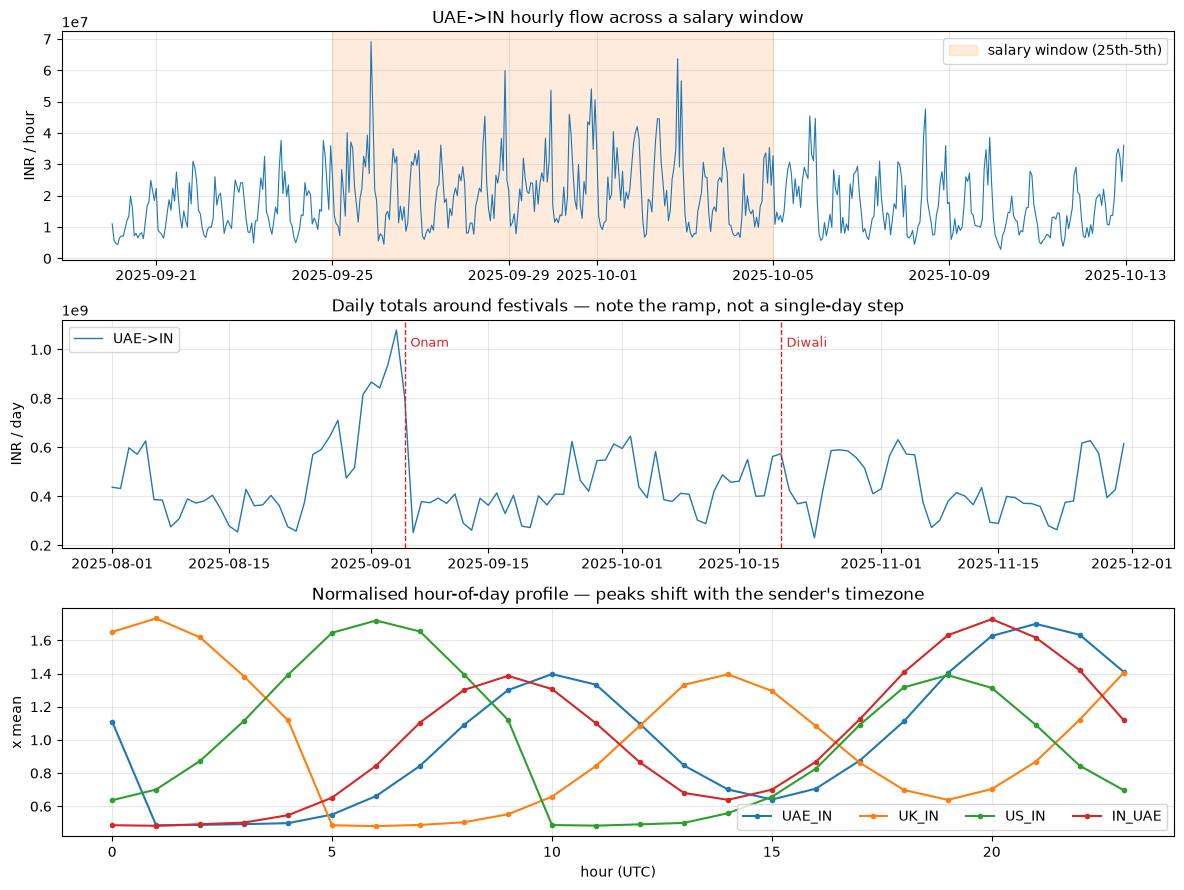

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

month = wide.loc["2025-09-20":"2025-10-12"]
axes[0].plot(month.index, month["UAE_IN"], lw=0.8)
axes[0].axvspan(pd.Timestamp("2025-09-25"), pd.Timestamp("2025-10-05"),
                alpha=0.15, color="tab:orange", label="salary window (25th-5th)")
axes[0].set_title("UAE->IN hourly flow across a salary window")
axes[0].set_ylabel("INR / hour"); axes[0].legend(loc="upper right")

daily = wide.resample("D").sum()
window = daily.loc["2025-08-01":"2025-11-30"]
axes[1].plot(window.index, window["UAE_IN"], lw=1.0, label="UAE->IN")
for name, label in [("2025-09-05", "Onam"), ("2025-10-20", "Diwali")]:
    axes[1].axvline(pd.Timestamp(name), color="tab:red", ls="--", lw=1)
    axes[1].annotate(label, (pd.Timestamp(name), window["UAE_IN"].max()),
                     textcoords="offset points", xytext=(4, -12), fontsize=9, color="tab:red")
axes[1].set_title("Daily totals around festivals — note the ramp, not a single-day step")
axes[1].set_ylabel("INR / day"); axes[1].legend(loc="upper left")

hourly_profile = wide.groupby(wide.index.hour).mean()
for corridor in gen.CORRIDORS:
    axes[2].plot(hourly_profile.index, hourly_profile[corridor] / hourly_profile[corridor].mean(),
                 marker="o", ms=3, label=corridor)
axes[2].set_title("Normalised hour-of-day profile — peaks shift with the sender's timezone")
axes[2].set_xlabel("hour (UTC)"); axes[2].set_ylabel("x mean"); axes[2].legend(ncol=4)

plt.tight_layout(); plt.show()

## 2. Features

Calendar features plus lags. The lags are why the train/test split below must be
**time-ordered**: a random shuffle would leak future values through them and
flatter every error metric in this notebook.

In [4]:
def build_features(series: pd.Series) -> pd.DataFrame:
    df = pd.DataFrame({"y": series})
    idx = series.index

    df["hour"] = idx.hour
    df["dayofweek"] = idx.day_of_week
    df["day"] = idx.day
    df["month"] = idx.month
    df["is_weekend_uae"] = idx.day_of_week.isin([4, 5]).astype(int)
    df["is_weekend_western"] = idx.day_of_week.isin([5, 6]).astype(int)
    df["in_salary_window"] = ((idx.day >= 25) | (idx.day <= 5)).astype(int)

    # Cyclical encodings so hour 23 and hour 0 are neighbours.
    df["hour_sin"] = np.sin(2 * np.pi * idx.hour / 24)
    df["hour_cos"] = np.cos(2 * np.pi * idx.hour / 24)

    # Days until the next festival, capped. The generator ramps over 10 days, so
    # the model is given the same horizon the signal actually has.
    festival_days = pd.DatetimeIndex(sorted(
        pd.Timestamp(d) for dates in gen.FESTIVALS.values() for d in dates))
    normalised = idx.normalize()
    days_to = np.full(len(idx), 60.0)
    for f in festival_days:
        delta = (f - normalised).days.to_numpy().astype(float)
        ahead = (delta >= 0) & (delta < days_to)
        days_to[ahead] = delta[ahead]
    df["days_to_festival"] = np.minimum(days_to, 30.0)

    for lag in (1, 2, 3, 24, 25, 48, 168):
        df[f"lag_{lag}"] = series.shift(lag)
    for window in (24, 168):
        df[f"roll_mean_{window}"] = series.shift(1).rolling(window).mean()
        df[f"roll_std_{window}"] = series.shift(1).rolling(window).std()

    return df.dropna()

features = {c: build_features(wide[c]) for c in gen.CORRIDORS}
print(f"{features['UAE_IN'].shape[1] - 1} features, {len(features['UAE_IN']):,} usable rows per corridor")
features["UAE_IN"].head(3)

21 features, 23,928 usable rows per corridor


,y,hour,dayofweek,day,month,is_weekend_uae,is_weekend_western,in_salary_window,hour_sin,hour_cos,...,lag_2,lag_3,lag_24,lag_25,lag_48,lag_168,roll_mean_24,roll_std_24,roll_mean_168,roll_std_168
ts,,,,,,,,,,,,,,,,,,,,,
2024-01-08 00:00:00,17382528.76,0,0,8,1,0,0,0,0.000000,1.000000,...,14635726.59,23482487.57,15404577.91,13831978.44,13731011.86,19968352.03,1.442206e+07,6.182321e+06,1.977374e+07,1.070995e+07
2024-01-08 01:00:00,6838185.48,1,0,8,1,0,0,0,0.258819,0.965926,...,27435401.34,14635726.59,5115259.14,15404577.91,5407646.89,11324818.05,1.450447e+07,6.209113e+06,1.975834e+07,1.071152e+07
2024-01-08 02:00:00,6085874.94,2,0,8,1,0,0,0,0.500000,0.866025,...,17382528.76,27435401.34,9731264.56,5115259.14,4938872.13,10839131.06,1.457626e+07,6.104923e+06,1.973164e+07,1.073824e+07


## 3. Quantile forecaster

One LightGBM model per corridor per quantile. The objective is the pinball loss,
so P90 is a genuine 90th-percentile estimate rather than a point forecast with a
margin bolted on.

The split is the last 20% of the series by time, held out entirely.

In [5]:
def fit_quantiles(df: pd.DataFrame, test_fraction: float = 0.2, seed: int = SEED):
    split = int(len(df) * (1 - test_fraction))
    train, test = df.iloc[:split], df.iloc[split:]
    X_cols = [c for c in df.columns if c != "y"]

    preds, models = {}, {}
    for q in QUANTILE_LEVELS:
        model = lgb.LGBMRegressor(
            objective="quantile", alpha=q,
            n_estimators=400, learning_rate=0.05,
            num_leaves=31, min_child_samples=30,
            subsample=0.9, subsample_freq=1, colsample_bytree=0.9,
            random_state=seed, verbose=-1,
        )
        model.fit(train[X_cols], train["y"])
        preds[q] = pd.Series(model.predict(test[X_cols]), index=test.index)
        models[q] = model
    return train, test, preds, models

fitted = {c: fit_quantiles(features[c]) for c in gen.CORRIDORS}
print("holdout:", fitted["UAE_IN"][1].index.min(), "..", fitted["UAE_IN"][1].index.max())

holdout: 2026-03-15 14:00:00 .. 2026-09-30 23:00:00


### Is the forecaster calibrated?

For a quantile model the question is not "how small is the error" but "does P90
actually sit above the outturn 90% of the time". Coverage far from the nominal
level means the pool sizing below rests on a broken estimate.

In [6]:
def pinball(y_true, y_pred, q):
    d = y_true - y_pred
    return np.mean(np.maximum(q * d, (q - 1) * d))

rows = []
for corridor, (train, test, preds, _) in fitted.items():
    y = test["y"]
    row = {"corridor": corridor, "holdout_hours": len(test)}
    for q in QUANTILE_LEVELS:
        row[f"P{int(q*100)}_coverage"] = float((y <= preds[q]).mean())
        row[f"P{int(q*100)}_pinball"] = pinball(y.to_numpy(), preds[q].to_numpy(), q)
    row["P50_MAE_pct_of_mean"] = float(np.abs(y - preds[0.50]).mean() / y.mean() * 100)
    rows.append(row)

calibration = pd.DataFrame(rows).set_index("corridor")
print("nominal coverage: P50 = 0.50, P90 = 0.90\n")
calibration.round(3)

nominal coverage: P50 = 0.50, P90 = 0.90



,holdout_hours,P50_coverage,P50_pinball,P90_coverage,P90_pinball,P50_MAE_pct_of_mean
corridor,,,,,,
UAE_IN,4786,0.500,1884997.006,0.864,1035300.066,20.292
UK_IN,4786,0.496,1556150.716,0.867,832699.000,20.404
US_IN,4786,0.502,2366121.174,0.875,1298427.568,20.156
IN_UAE,4786,0.503,961406.646,0.862,511502.545,21.752


### What the calibration table says

P50 coverage lands within half a point of nominal on every corridor. **P90
coverage comes in at roughly 0.86-0.88 against a nominal 0.90** — the P90 model
is mildly under-dispersed, so it sits slightly too low and the outturn exceeds it
a little more often than one time in ten.

That matters for §5, where P90 is used as the pool size: a pool sized to this
P90 will be short slightly more often than the nominal 10% of windows. It is not
fatal for a comparison at matched risk, because §4 sizes both designs from the
realised distribution rather than from the model. It is a real finding and it is
recorded here rather than rounded away. Closing the gap is a Phase 1 task:
conformal calibration of the quantile estimate on a validation fold.

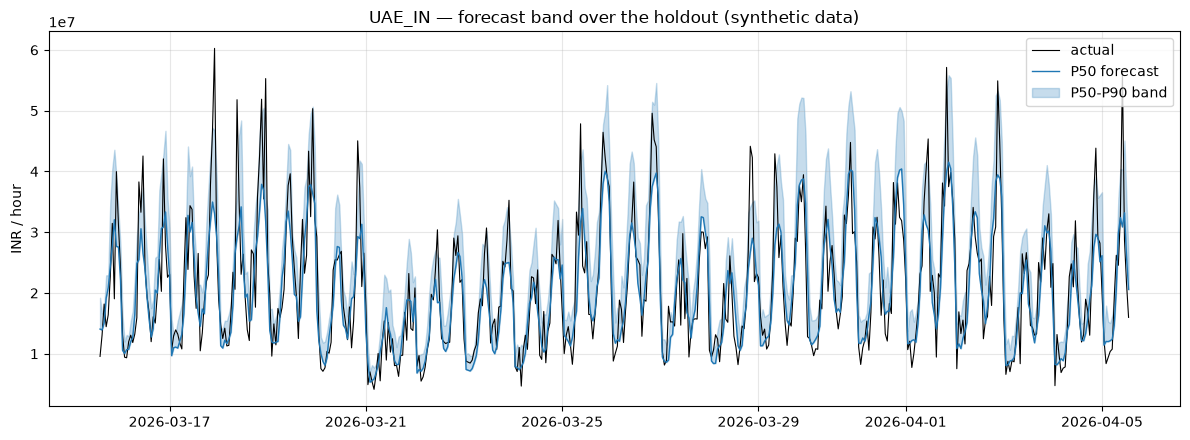

In [7]:
corridor = "UAE_IN"
train, test, preds, _ = fitted[corridor]
view = slice(None, 24 * 21)  # first three weeks of the holdout

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(test.index[view], test["y"].iloc[view], lw=0.8, color="black", label="actual")
ax.plot(test.index[view], preds[0.50].iloc[view], lw=1.0, color="tab:blue", label="P50 forecast")
ax.fill_between(test.index[view], preds[0.50].iloc[view], preds[0.90].iloc[view],
                alpha=0.25, color="tab:blue", label="P50-P90 band")
ax.set_title(f"{corridor} — forecast band over the holdout (synthetic data)")
ax.set_ylabel("INR / hour"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 4. Pool sizing — separate buffers versus one shared pool

This is the central quantitative claim of the pitch, so it gets stated carefully.

**What is being compared.** Two ways to cover the same INR payout demand at the
**same shortfall risk**:

- *Separate buffers* — each inbound provider sizes its own buffer independently
  against its own corridor demand at quantile `q`. The total capital tied up is
  the sum of those buffers.
- *One shared pool* — a single buffer covers aggregate demand at the same
  quantile `q`, after the outbound `IN→UAE` flow has been netted against the
  inbound flows within the window.

**Where the benefit comes from.** Two separate effects, and the notebook reports
them separately because conflating them would overstate either one:

1. *Diversification* — corridor demands are imperfectly correlated, so the
   quantile of the sum is less than the sum of the quantiles.
2. *Netting* — the opposite `IN→UAE` flow supplies INR into the pool within the
   same window, reducing the net requirement.

**Matched risk is the whole point.** Comparing buffer sizes at different
shortfall probabilities would be meaningless. Both designs are sized at the same
`q`, and §4.3 checks the realised shortfall frequency of each on the holdout to
confirm the risk really was matched.

In [8]:
NETTING_WINDOW = "4h"   # short enough that opposite flows genuinely overlap
QUANTILE = 0.99         # per-window shortfall probability of 1%

INBOUND = ["UAE_IN", "UK_IN", "US_IN"]
OUTBOUND = ["IN_UAE"]

windowed = wide.resample(NETTING_WINDOW).sum()

separate_buffers = windowed[INBOUND].quantile(QUANTILE)
separate_total = separate_buffers.sum()

# Diversification only: aggregate the inbound corridors, no netting.
pooled_no_netting = windowed[INBOUND].sum(axis=1).quantile(QUANTILE)

# Diversification and netting: the outbound flow supplies INR into the pool.
net_requirement = windowed[INBOUND].sum(axis=1) - windowed[OUTBOUND].sum(axis=1)
pooled_netted = net_requirement.quantile(QUANTILE)

summary = pd.DataFrame({
    "buffer_INR": [separate_total, pooled_no_netting, pooled_netted],
    "vs_separate": [1.0, pooled_no_netting / separate_total, pooled_netted / separate_total],
}, index=["separate per-provider buffers", "shared pool (diversification only)",
          "shared pool (diversification + netting)"])
summary["reduction_%"] = (1 - summary["vs_separate"]) * 100

print(f"netting window = {NETTING_WINDOW}   matched shortfall risk = {(1-QUANTILE):.1%} per window\n")
print("per-provider buffers at the same quantile:")
print((separate_buffers / 1e6).round(2).to_string(), "(INR millions)\n")
summary.assign(buffer_INR_millions=(summary.buffer_INR / 1e6).round(2)).drop(columns="buffer_INR").round(3)

netting window = 4h   matched shortfall risk = 1.0% per window

per-provider buffers at the same quantile:
corridor
UAE_IN    185.56
UK_IN     149.01
US_IN     235.58 (INR millions)



,vs_separate,reduction_%,buffer_INR_millions
separate per-provider buffers,1.000,0.000,570.15
shared pool (diversification only),0.730,27.048,415.94
shared pool (diversification + netting),0.628,37.219,357.95


### 4.1 How sensitive is this to the two choices that drive it?

The netting window and the quantile are judgement calls, so the result is shown
across a grid rather than at one flattering point.

In [9]:
grid = []
for window in ["1h", "2h", "4h", "8h", "24h"]:
    w = wide.resample(window).sum()
    for q in [0.95, 0.99, 0.999]:
        sep = w[INBOUND].quantile(q).sum()
        net = (w[INBOUND].sum(axis=1) - w[OUTBOUND].sum(axis=1)).quantile(q)
        grid.append({"window": window, "quantile": q, "reduction_%": (1 - net / sep) * 100})

sens = pd.DataFrame(grid).pivot(index="window", columns="quantile", values="reduction_%")
sens = sens.reindex(["1h", "2h", "4h", "8h", "24h"])
print("buffer reduction (%) from pooling + netting, by window and matched quantile")
sens.round(1)

buffer reduction (%) from pooling + netting, by window and matched quantile


quantile,0.950,0.990,0.999
window,,,
1h,32.7,38.8,43.8
2h,32.5,38.1,39.7
4h,31.2,37.2,38.3
8h,23.2,23.8,28.2
24h,16.8,13.9,19.3


### 4.2 Where does the benefit actually come from?

Correlation between corridors is the mechanism behind the diversification half.
If these were perfectly correlated the benefit would collapse toward zero, so it
is worth looking at directly rather than asserting it.

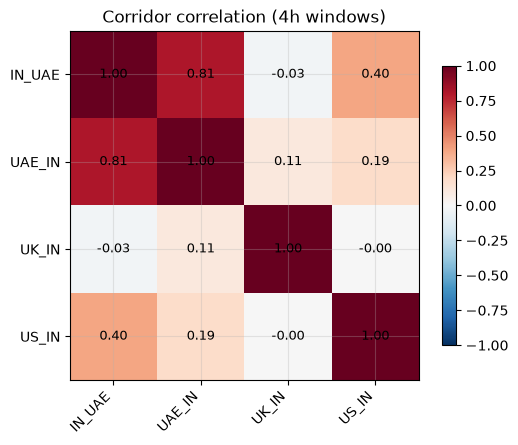

In [10]:
corr = windowed.corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title(f"Corridor correlation ({NETTING_WINDOW} windows)")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

### 4.3 Was the risk really matched?

Sizing both designs at the same quantile should give them the same realised
shortfall frequency. If it does not, the comparison in §4 is not like-for-like
and the reduction figure is not meaningful.

In [11]:
def realised_shortfall(demand: pd.Series, buffer: float) -> float:
    return float((demand > buffer).mean())

separate_shortfall = float(
    np.mean([realised_shortfall(windowed[c], separate_buffers[c]) for c in INBOUND])
)
pooled_shortfall = realised_shortfall(net_requirement, pooled_netted)

check = pd.DataFrame({
    "design": ["separate buffers (mean across providers)", "shared netted pool"],
    "target_shortfall": [1 - QUANTILE, 1 - QUANTILE],
    "realised_shortfall": [separate_shortfall, pooled_shortfall],
}).set_index("design")
check.round(4)

,target_shortfall,realised_shortfall
design,,
separate buffers (mean across providers),0.01,0.0101
shared netted pool,0.01,0.0101


## 5. Connecting the forecaster to the pool

Sections 3 and 4 are two halves of one mechanism: the agent forecasts the P90 of
net demand for the next window, and the pool is sized to that forecast rather
than to a static buffer. A static buffer has to cover the worst window in the
whole history; a forecast-sized pool only has to cover the next one.

Below, the same matched-risk comparison is run against the forecast rather than
against realised history.

static pool sized to the holdout's 99.0% quantile : INR 356.8m
mean forecast-sized pool (P90 per window)                 : INR 249.1m
windows where actual exceeded the P90 forecast            : 0.7%
mean idle capital avoided versus the static buffer        : INR 107.7m


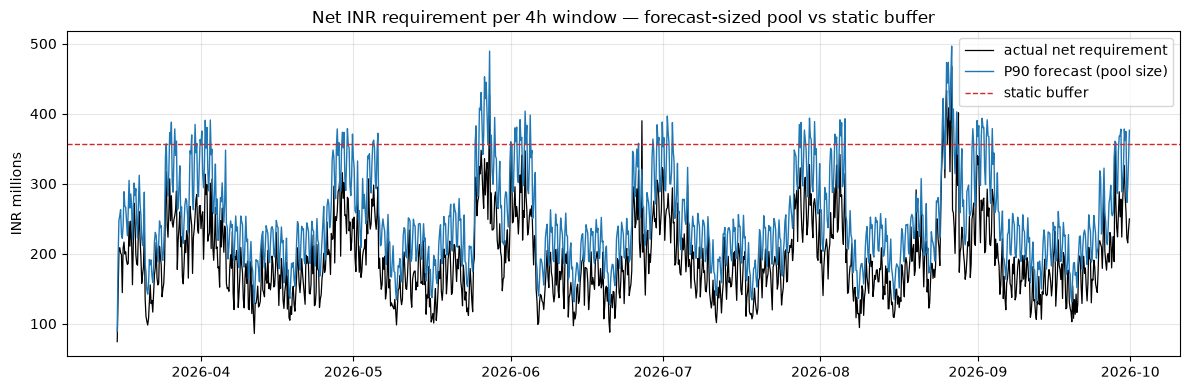

In [12]:
# P90 forecast of net requirement, aggregated to the netting window.
forecast_p90 = pd.DataFrame({c: fitted[c][2][0.90] for c in gen.CORRIDORS}).dropna()
fc_windowed = forecast_p90.resample(NETTING_WINDOW).sum()
actual_windowed = pd.DataFrame(
    {c: fitted[c][1]["y"] for c in gen.CORRIDORS}
).dropna().resample(NETTING_WINDOW).sum()

fc_net = fc_windowed[INBOUND].sum(axis=1) - fc_windowed[OUTBOUND].sum(axis=1)
actual_net = actual_windowed[INBOUND].sum(axis=1) - actual_windowed[OUTBOUND].sum(axis=1)

static_buffer = actual_net.quantile(QUANTILE)
forecast_shortfall = float((actual_net > fc_net).mean())
mean_forecast_pool = float(fc_net.mean())

print(f"static pool sized to the holdout's {QUANTILE:.1%} quantile : INR {static_buffer/1e6:,.1f}m")
print(f"mean forecast-sized pool (P90 per window)                 : INR {mean_forecast_pool/1e6:,.1f}m")
print(f"windows where actual exceeded the P90 forecast            : {forecast_shortfall:.1%}")
print(f"mean idle capital avoided versus the static buffer        : "
      f"INR {(static_buffer - mean_forecast_pool)/1e6:,.1f}m")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(actual_net.index, actual_net / 1e6, lw=0.9, color="black", label="actual net requirement")
ax.plot(fc_net.index, fc_net / 1e6, lw=1.0, color="tab:blue", label="P90 forecast (pool size)")
ax.axhline(static_buffer / 1e6, color="tab:red", ls="--", lw=1, label="static buffer")
ax.set_title(f"Net INR requirement per {NETTING_WINDOW} window — forecast-sized pool vs static buffer")
ax.set_ylabel("INR millions"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 6. What this does and does not show

**Shown, on synthetic data:**

- A quantile forecaster can be fitted on this series. §3 reports realised
  coverage on a time-ordered holdout: P50 is well calibrated, **P90 is not
  quite — it covers 0.86-0.88 against a nominal 0.90**, so a pool sized to
  this P90 runs short a little more often than advertised.
- Pooling and netting reduce the required buffer at matched shortfall risk, and
  §4.3 confirms the risk really was matched.
- The reduction is sensitive to the netting window and the quantile — §4.1 gives
  the range rather than one number.

**Not shown, and not claimed:**

- That any of this transfers to real corridor flows. The generator contains no
  regime changes, no policy shocks, no competitor response and no correlated
  crisis across all corridors at once. A model that looks good here has not been
  shown to work on real data.
- Any rupee or dollar capital saving for a real institution. Converting a buffer
  ratio into money needs a balance-sheet size and a cost of capital that this
  project does not have and will not assume.
- Any operational cost of running a shared pool, which a real decision would need
  and which is excluded here.
- That members can always draw on the pool under stress. §4 assumes no
  member-level gating; if gating exists, the effective pooled buffer is smaller
  than modelled.

Any slide or submission text citing the §4 figure must carry the same
qualification. See [`docs/ASSUMPTIONS.md`](../../docs/ASSUMPTIONS.md) §3.